# 04 — Explainability: Grad-CAM and LIME
**KhabarNazar — Image Analysis Module**

The final model (`models/resnet18_final.pth`) says *real* or *fake*. These two methods show **why**:

| Method | How it works | Output |
|---|---|---|
| **Grad-CAM** | Takes the gradient of the predicted class with respect to the last convolutional block (`layer4`) and uses it to weight that block's feature maps. | Heatmap: red = regions that pushed the model most towards its prediction |
| **LIME** | Splits the image into superpixels, hides random groups of them ~1,000 times, and fits a simple model to see which superpixels change the prediction most. | Green outlines around the 5 most important regions |

Grad-CAM looks *inside* the network; LIME treats it as a black box. When both point to the same regions,
the explanation is more trustworthy.

Each figure shows correct real, correct fake, and misclassified examples from all three test sets.
Section 5 explains **any image** you choose — useful for a live demo.

In [1]:
from pathlib import Path

import cv2
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
from torch import nn
from torchvision import datasets, models, transforms
from PIL import Image
from lime import lime_image
from skimage.segmentation import mark_boundaries

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
P = ROOT / "data" / "processed"
MODELS = ROOT / "models"
OUTPUTS = ROOT / "outputs"; OUTPUTS.mkdir(exist_ok=True)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
CLASSES = ["fake", "real"]

model = models.resnet18(weights=None)
model.fc = nn.Linear(model.fc.in_features, 2)
model.load_state_dict(torch.load(MODELS / "resnet18_final.pth", map_location="cpu", weights_only=True))
model = model.to(device).eval()
print("Loaded final model on", device)

Loaded final model on cuda


## 1. Input preparation
Same pipeline as training: Tiny-GenImage images are resized to 256 px first; all other images (including any new
photo) are brought to at most 512 px on the shorter side, then the centre 224×224 crop is used.

In [2]:
to_tensor = transforms.Compose([transforms.ToTensor(), transforms.Normalize(MEAN, STD)])

def resize_short(img, size):
    w, h = img.size
    k = size / min(w, h)
    return img.resize((max(1, round(w * k)), max(1, round(h * k))), Image.BICUBIC)

def prepare(img, mode="crop"):
    # returns the 224x224 RGB image the model actually sees
    img = img.convert("RGB")
    if mode == "tiny":
        img = resize_short(img, 256)
    elif min(img.size) > 512:
        img = resize_short(img, 512)
    elif min(img.size) < 224:
        img = resize_short(img, 224)
    return transforms.CenterCrop(224)(img)

@torch.no_grad()
def predict_images(images):
    # images: list of 224x224 PIL images -> class probabilities (N, 2)
    out = []
    for i in range(0, len(images), 64):
        batch = torch.stack([to_tensor(im) for im in images[i:i + 64]]).to(device)
        out.append(torch.softmax(model(batch), 1).cpu())
    return torch.cat(out).numpy()

## 2. Grad-CAM

In [3]:
class GradCAM:
    # Hooks one layer and records its activations (forward pass) and gradients (backward pass)
    def __init__(self, model, layer):
        self.model, self.acts, self.grads = model, None, None
        self.handle = layer.register_forward_hook(self._hook)

    def _hook(self, module, inputs, output):
        self.acts = output.detach()
        if output.requires_grad:
            output.register_hook(lambda g: setattr(self, "grads", g.detach()))

    def __call__(self, x):
        self.model.zero_grad(set_to_none=True)
        logits = self.model(x)
        probs = torch.softmax(logits, 1)[0].detach().cpu().numpy()
        cls = int(logits.argmax(1))
        logits[0, cls].backward()                              # gradient of the predicted class
        weights = self.grads.mean(dim=(2, 3), keepdim=True)    # importance of each of the 512 channels
        cam = F.relu((weights * self.acts).sum(1))[0]          # weighted sum of feature maps (7x7)
        cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
        return cam.cpu().numpy(), cls, probs

gradcam = GradCAM(model, model.layer4[-1])                    # last block of ResNet18

def overlay(img_rgb, cam, alpha=0.45):
    h, w = img_rgb.shape[:2]
    heat = cv2.applyColorMap(np.uint8(255 * cv2.resize(cam, (w, h))), cv2.COLORMAP_JET)
    heat = cv2.cvtColor(heat, cv2.COLOR_BGR2RGB)
    return np.uint8(alpha * heat + (1 - alpha) * img_rgb)

## 3. LIME

In [4]:
explainer = lime_image.LimeImageExplainer(random_state=0)

def lime_predict(arrays):
    # LIME passes a batch of numpy images; return class probabilities
    return predict_images([Image.fromarray(a.astype(np.uint8)) for a in arrays])

def lime_explain(img, label, samples=1000, features=5):
    exp = explainer.explain_instance(np.array(img), lime_predict, labels=(label,), top_labels=None,
                                     hide_color=0, num_samples=samples, batch_size=64)
    temp, mask = exp.get_image_and_mask(label, positive_only=True, num_features=features, hide_rest=False)
    return mark_boundaries(temp / 255.0, mask, color=(0, 1, 0))

In [5]:
def show_explanations(items, title, file):
    # items: list of (224x224 PIL image, true label index or None, caption)
    fig, axes = plt.subplots(len(items), 3, figsize=(11, 3.6 * len(items)), squeeze=False)
    for r, (img, true, caption) in enumerate(items):
        arr = np.array(img)
        cam, pred, probs = gradcam(to_tensor(img).unsqueeze(0).to(device))
        lime_img = lime_explain(img, pred)
        if true is None:
            colour, verdict = "black", ""
        else:
            colour = "green" if pred == true else "red"
            verdict = "correct" if pred == true else "WRONG"
        true_txt = "" if true is None else f" | true: {CLASSES[true]}"
        axes[r, 0].imshow(arr); axes[r, 0].set_title(f"{caption}{true_txt}", fontsize=9)
        axes[r, 1].imshow(overlay(arr, cam))
        axes[r, 1].set_title(f"Grad-CAM: {CLASSES[pred]} ({probs[pred]:.0%}) {verdict}", fontsize=9, color=colour)
        axes[r, 2].imshow(lime_img); axes[r, 2].set_title("LIME: top 5 regions", fontsize=9)
        for a in axes[r]:
            a.axis("off")
    fig.suptitle(title, fontsize=13)
    plt.tight_layout(); plt.savefig(OUTPUTS / file, dpi=110, bbox_inches="tight"); plt.show()

def pick_examples(folder, mode, n_sample=300, seed=0):
    # From a random sample: 2 correct fakes, 2 correct reals, 2 mistakes
    ds = datasets.ImageFolder(folder)
    idx = np.random.RandomState(seed).choice(len(ds), n_sample, replace=False)
    paths = [ds.samples[i][0] for i in idx]
    y = np.array([ds.samples[i][1] for i in idx])
    imgs = [prepare(Image.open(p), mode) for p in paths]
    pred = predict_images(imgs).argmax(1)
    chosen = [i for i in range(n_sample) if y[i] == 0 and pred[i] == 0][:2]
    chosen += [i for i in range(n_sample) if y[i] == 1 and pred[i] == 1][:2]
    chosen += [i for i in range(n_sample) if pred[i] != y[i]][:2]
    return [(imgs[i], int(y[i]), Path(paths[i]).stem[:26]) for i in chosen]

## 4. Explanations on the three test sets

  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

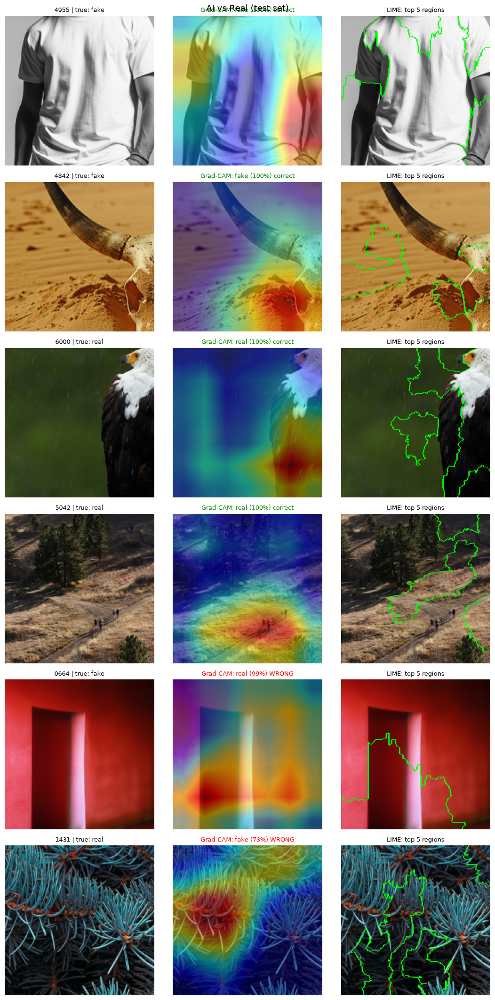

In [6]:
items = pick_examples(P / "ai_vs_real" / "test", "crop")
show_explanations(items, "AI vs Real (test set)", "04_explain_ai_vs_real.png")

  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

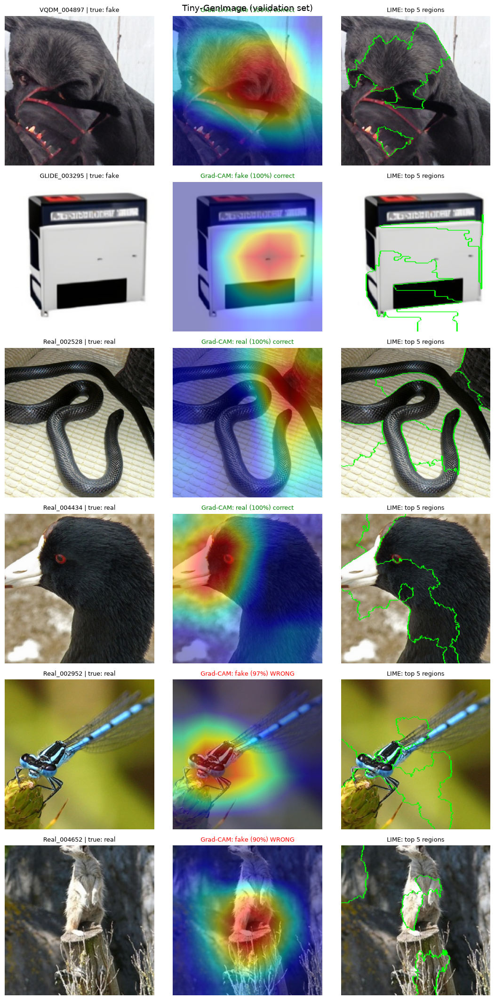

In [7]:
items = pick_examples(P / "tiny_genimage" / "val", "tiny")
show_explanations(items, "Tiny-GenImage (validation set)", "04_explain_tiny_genimage.png")

  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

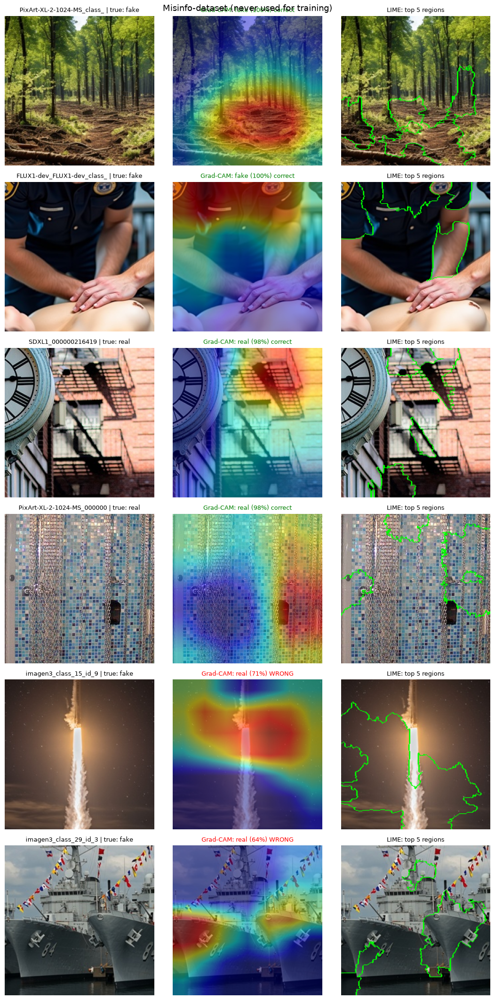

In [8]:
items = pick_examples(P / "misinfo" / "test", "crop")
show_explanations(items, "Misinfo-dataset (never used for training)", "04_explain_misinfo.png")

**How to read these figures**
- Grad-CAM uses a 7×7 grid, so its heatmaps are coarse: they show *roughly where* the evidence is.
- LIME works on superpixels, so its regions follow object edges more closely.
- For fakes, look for attention on textures that generators struggle with (skin, hair, backgrounds, text, hands).
  For mistakes, check whether the model focused on something irrelevant — that explains *why* it was wrong.

## 5. Explain any image (live demo)
Put the full path of any image in `IMAGE_PATH` and run the cell. If the path does not exist, a Misinfo image is used.

  0%|          | 0/1000 [00:00<?, ?it/s]

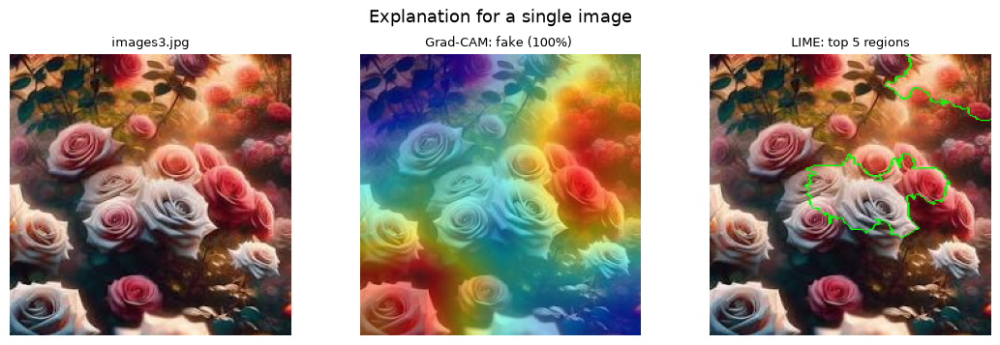

In [12]:
IMAGE_PATH = r"E:\FYP\test_images\images3.jpg"

path = Path(IMAGE_PATH)
if not path.exists():
    path = sorted((P / "misinfo" / "test" / "fake").glob("*.jpg"))[0]
    print("Path not found - using example:", path.name)
img = prepare(Image.open(path), "crop")
show_explanations([(img, None, path.name[:30])], "Explanation for a single image", "04_explain_single.png")

## 6. Summary
- Grad-CAM and LIME are implemented on the final model and applied to all three test sets.
- All figures are saved in `outputs/` (`04_explain_*.png`).
- Section 5 can explain any new image, which is the same function the KhabarNazar backend will use.